# Telecom Customer Churn Prediction

Original analysis by Josephine Jesuraj. Prepared for the public data science portfolio.

# Telecom Customer Churn Prediction
This notebook analyzes customer churn and compares machine learning models for identifying customers who may leave.

## 1. Setup

This section loads the libraries needed for data preparation, visualization, modeling, and evaluation.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, roc_curve, classification_report
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Dataset

The customer churn dataset is loaded into a pandas DataFrame so its structure and contents can be reviewed before analysis.


In [2]:
from pathlib import Path
DATA_PATH = Path("data/telco_customer_churn.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected dataset: {DATA_PATH}. Run from the project folder.")
df = pd.read_csv(DATA_PATH)
print("Loaded dataset:", DATA_PATH, "Shape:", df.shape)
display(df.head())

Loaded local dataset: WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Initial Data Inspection

The dataset is checked for size, data types, duplicates, missing values, and churn distribution. This identifies data-quality issues before preprocessing.


In [3]:
print("Rows and columns:", df.shape)
print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nRaw missing values:")
display(df.isna().sum().to_frame("missing").query("missing > 0"))

print("\nChurn distribution:")
display(df["Churn"].value_counts().to_frame("count"))
display((df["Churn"].value_counts(normalize=True) * 100).round(2).to_frame("percent"))

Rows and columns: (7043, 21)

Duplicate rows: 0

Data types:


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Raw missing values:


,missing



Churn distribution:


,count
Churn,
No,5174
Yes,1869


,percent
Churn,
No,73.46
Yes,26.54


## 4. Data Cleaning

`TotalCharges` is converted to numeric because blank entries cause the column to be stored as text. Missing values are handled during preprocessing.

`Churn` is converted from `Yes/No` to `1/0`, and `customerID` is removed because it is an identifier rather than a predictor.


In [4]:
data = df.copy()

# Convert TotalCharges to numeric; blanks become NaN.
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

print("Missing TotalCharges after numeric conversion:", data["TotalCharges"].isna().sum())
display(data.loc[data["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head(15))

# Encode target.
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

# Remove identifier from modeling data.
data = data.drop(columns=["customerID"])

print("\nCleaned shape:", data.shape)

Missing TotalCharges after numeric conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No



Cleaned shape: (7043, 20)


## 5. Exploratory Data Analysis

Churn is examined by contract type, tenure, monthly charges, and payment method. These comparisons help identify patterns for modeling and business interpretation.


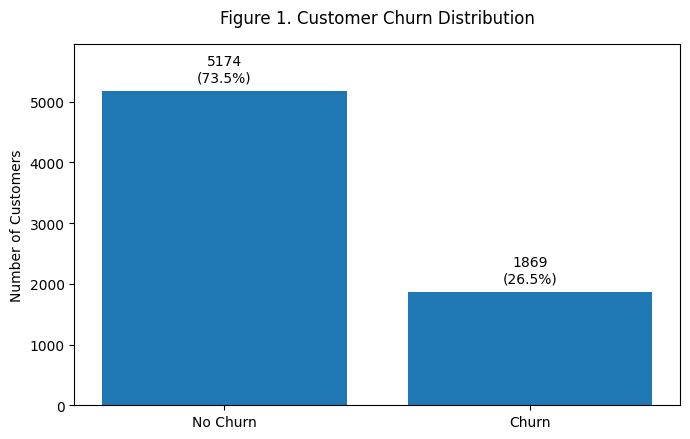

In [5]:
# Figure 1: Customer Churn Distribution
counts = data["Churn"].value_counts().sort_index()
labels = ["No Churn", "Churn"]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(labels, counts.values)

ax.set_title("Figure 1. Customer Churn Distribution", pad=15)
ax.set_ylabel("Number of Customers")

# Add extra space above the tallest bar
ax.set_ylim(0, counts.max() * 1.15)

# Add count and percentage above each bar
for bar, value in zip(bars, counts.values):
    pct = value/counts.sum() * 100
    ax.text(bar.get_x() + bar.get_width() / 2,
        value + counts.max() * 0.02,
        f"{value}\n({pct:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

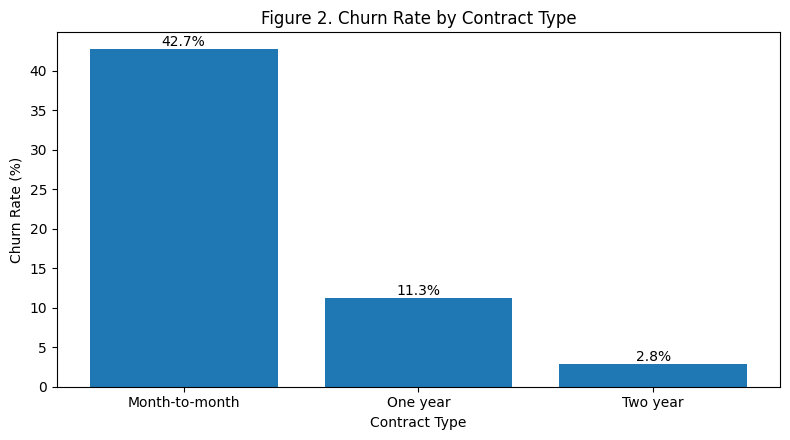

,Churn Rate (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


In [6]:
# Figure 2: Churn Rate by Contract Type
contract_rate = (
    data.groupby("Contract", observed=False)["Churn"]
        .mean()
        .sort_values(ascending=False)
        .mul(100)
)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(contract_rate.index, contract_rate.values)
ax.set_title("Figure 2. Churn Rate by Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_xlabel("Contract Type")

for bar, value in zip(bars, contract_rate.values):
    ax.text(bar.get_x() + bar.get_width()/2, value, f"{value:.1f}%",
            ha="center", va="bottom")

plt.tight_layout()
plt.show()

display(contract_rate.round(2).to_frame("Churn Rate (%)"))

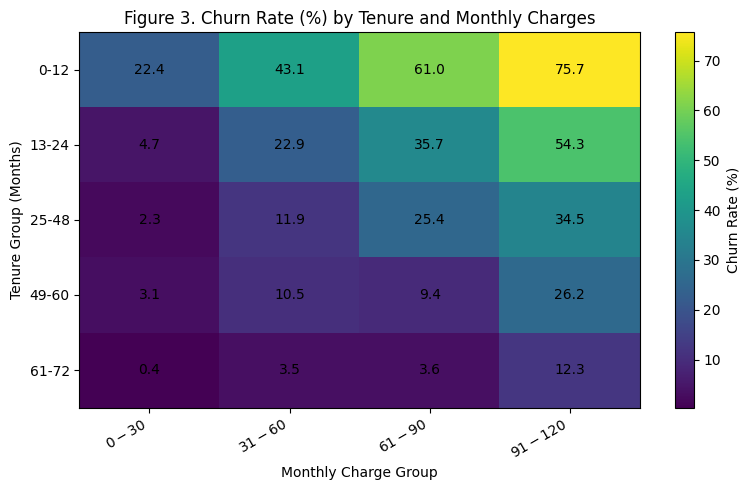

MonthlyChargeGroup,$0-$30,$31-$60,$61-$90,$91-$120
TenureGroup,,,,
0-12,22.4,43.1,61.0,75.7
13-24,4.7,22.9,35.7,54.3
25-48,2.3,11.9,25.4,34.5
49-60,3.1,10.5,9.4,26.2
61-72,0.4,3.5,3.6,12.3


In [7]:
# Figure 3: Churn Rate by Tenure Group and Monthly Charge Group
eda = data.copy()

eda["TenureGroup"] = pd.cut(
    eda["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=["0-12", "13-24", "25-48", "49-60", "61-72"]
)

eda["MonthlyChargeGroup"] = pd.cut(
    eda["MonthlyCharges"],
    bins=[0, 30, 60, 90, 120],
    labels=["$0-$30", "$31-$60", "$61-$90", "$91-$120"],
    include_lowest=True
)

heat = pd.pivot_table(
    eda,
    values="Churn",
    index="TenureGroup",
    columns="MonthlyChargeGroup",
    aggfunc="mean",
    observed=False
) * 100

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(heat.values, aspect="auto")
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels(heat.columns, rotation=30, ha="right")
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
ax.set_xlabel("Monthly Charge Group")
ax.set_ylabel("Tenure Group (Months)")
ax.set_title("Figure 3. Churn Rate (%) by Tenure and Monthly Charges")

for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        val = heat.iloc[i, j]
        if pd.notna(val):
            ax.text(j, i, f"{val:.1f}", ha="center", va="center")

fig.colorbar(im, ax=ax, label="Churn Rate (%)")
plt.tight_layout()
plt.show()

display(heat.round(1))

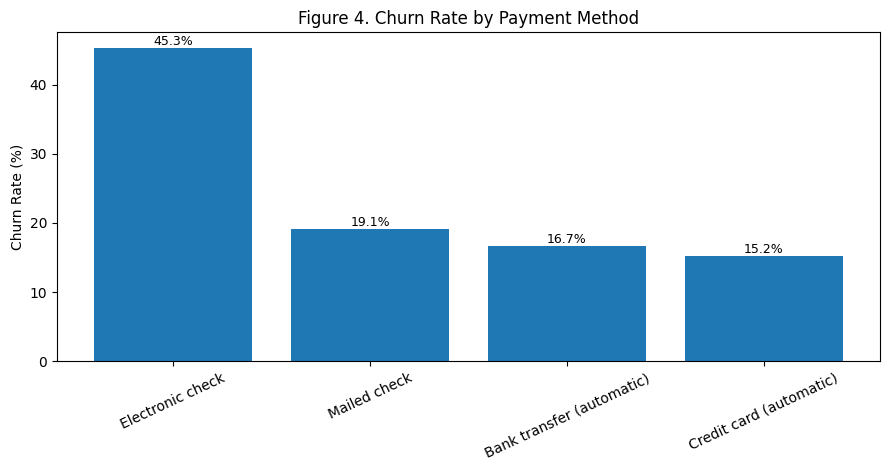

,Churn Rate (%)
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24


In [8]:
# Figure 4: Churn Rate by Payment Method
payment_rate = (
    data.groupby("PaymentMethod", observed=False)["Churn"]
        .mean()
        .sort_values(ascending=False)
        .mul(100)
)

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(payment_rate.index, payment_rate.values)
ax.set_title("Figure 4. Churn Rate by Payment Method")
ax.set_ylabel("Churn Rate (%)")
ax.tick_params(axis="x", rotation=25)

for bar, value in zip(bars, payment_rate.values):
    ax.text(bar.get_x() + bar.get_width()/2, value, f"{value:.1f}%",
            ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

display(payment_rate.round(2).to_frame("Churn Rate (%)"))

## 6. Feature Engineering

Tenure and payment information are grouped into additional categories to make customer patterns easier to analyze while retaining the original variables for modeling.


In [9]:
model_data = data.copy()

model_data["TenureGroup"] = pd.cut(
    model_data["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=["0-12", "13-24", "25-48", "49-60", "61-72"]
).astype(str)

def payment_category(value):
    if "automatic" in value.lower():
        return "Automatic"
    if value == "Electronic check":
        return "Electronic Check"
    return "Mailed Check"

model_data["PaymentCategory"] = model_data["PaymentMethod"].apply(payment_category)

display(model_data[["tenure", "TenureGroup", "PaymentMethod", "PaymentCategory"]].head())

,tenure,TenureGroup,PaymentMethod,PaymentCategory
0,1,0-12,Electronic check,Electronic Check
1,34,25-48,Mailed check,Mailed Check
2,2,0-12,Mailed check,Mailed Check
3,45,25-48,Bank transfer (automatic),Automatic
4,2,0-12,Electronic check,Electronic Check


## 7. Train/Test Split and Preprocessing

The data is divided into 80% training and 20% testing using stratification. Numeric variables are imputed and standardized, while categorical variables are imputed and one-hot encoded.

SMOTE is applied only to training data to address class imbalance without introducing information from the test set.


In [10]:
X = model_data.drop(columns="Churn")
y = model_data["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Training churn rate:", round(y_train.mean(), 4))
print("Test churn rate:", round(y_test.mean(), 4))

Training shape: (5634, 21)
Test shape: (1409, 21)
Training churn rate: 0.2654
Test churn rate: 0.2654


## 8. Evaluation Metrics

Models are evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices. Multiple metrics are used because churn is an imbalanced classification problem.


In [11]:
def evaluate_predictions(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_prob)
    }

def print_report(name, y_true, y_pred):
    print(f"\n{name}")
    print("-" * len(name))
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    print("Confusion matrix:")
    print(confusion_matrix(y_true, y_pred))

## 9. Dummy Baseline

A Dummy Classifier provides a simple baseline and shows whether the machine learning models improve on predicting only the majority class.


In [12]:
dummy_pipe = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

dummy_pipe.fit(X_train, y_train)
dummy_pred = dummy_pipe.predict(X_test)

# DummyClassifier does provide predict_proba after fitting.
dummy_prob = dummy_pipe.predict_proba(X_test)[:, 1]

dummy_result = evaluate_predictions(
    "Dummy Baseline", y_test, dummy_pred, dummy_prob
)
print_report("Dummy Baseline", y_test, dummy_pred)
display(pd.DataFrame([dummy_result]).round(4))


Dummy Baseline
--------------
              precision    recall  f1-score   support

           0     0.7346    1.0000    0.8470      1035
           1     0.0000    0.0000    0.0000       374

    accuracy                         0.7346      1409
   macro avg     0.3673    0.5000    0.4235      1409
weighted avg     0.5396    0.7346    0.6222      1409

Confusion matrix:
[[1035    0]
 [ 374    0]]


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Dummy Baseline,0.7346,0.0,0.0,0.0,0.5


## 10. Logistic Regression

Logistic Regression is trained as an interpretable classification model. SMOTE is included in the training pipeline to improve learning from the minority churn class.


In [13]:
lr_pipe = ImbPipeline(steps=[
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        random_state=RANDOM_STATE
    ))
])

lr_pipe.fit(X_train, y_train)
lr_pred = lr_pipe.predict(X_test)
lr_prob = lr_pipe.predict_proba(X_test)[:, 1]

lr_result = evaluate_predictions(
    "Logistic Regression", y_test, lr_pred, lr_prob
)

print_report("Logistic Regression", y_test, lr_pred)
display(pd.DataFrame([lr_result]).round(4))


Logistic Regression
-------------------
              precision    recall  f1-score   support

           0     0.9059    0.7256    0.8058      1035
           1     0.5103    0.7914    0.6205       374

    accuracy                         0.7431      1409
   macro avg     0.7081    0.7585    0.7132      1409
weighted avg     0.8009    0.7431    0.7566      1409

Confusion matrix:
[[751 284]
 [ 78 296]]


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.7431,0.5103,0.7914,0.6205,0.8414


## 11. Random Forest with Hyperparameter Tuning

Random Forest captures nonlinear relationships and interactions among customer features. GridSearchCV is used to select model settings based on cross-validated ROC-AUC.


In [14]:
rf_pipe = ImbPipeline(steps=[
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

rf_param_grid = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [None, 12],
    "model__max_features": ["sqrt"],
    "model__min_samples_leaf": [1, 2]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_search = GridSearchCV(
    rf_pipe,
    param_grid=rf_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=1,
    refit=True
)

rf_search.fit(X_train, y_train)
rf_best = rf_search.best_estimator_

print("Best Random Forest parameters:", rf_search.best_params_)
print("Best Random Forest CV ROC-AUC:", round(rf_search.best_score_, 4))

rf_pred = rf_best.predict(X_test)
rf_prob = rf_best.predict_proba(X_test)[:, 1]

rf_result = evaluate_predictions(
    "Random Forest", y_test, rf_pred, rf_prob
)

print_report("Random Forest", y_test, rf_pred)
display(pd.DataFrame([rf_result]).round(4))

Best Random Forest parameters: {'model__max_depth': 12, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Best Random Forest CV ROC-AUC: 0.8381

Random Forest
-------------
              precision    recall  f1-score   support

           0     0.8595    0.8155    0.8369      1035
           1     0.5527    0.6310    0.5893       374

    accuracy                         0.7665      1409
   macro avg     0.7061    0.7232    0.7131      1409
weighted avg     0.7780    0.7665    0.7712      1409

Confusion matrix:
[[844 191]
 [138 236]]


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,0.7665,0.5527,0.631,0.5893,0.8346


## 12. XGBoost

XGBoost is trained as a gradient-boosting model to capture complex relationships and provide another model for comparison.


In [15]:
xgb_pipe = ImbPipeline(steps=[
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.85,
        colsample_bytree=0.85,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

xgb_pipe.fit(X_train, y_train)
xgb_pred = xgb_pipe.predict(X_test)
xgb_prob = xgb_pipe.predict_proba(X_test)[:, 1]

xgb_result = evaluate_predictions(
    "XGBoost", y_test, xgb_pred, xgb_prob
)

print_report("XGBoost", y_test, xgb_pred)
display(pd.DataFrame([xgb_result]).round(4))


XGBoost
-------
              precision    recall  f1-score   support

           0     0.8564    0.8473    0.8519      1035
           1     0.5896    0.6070    0.5982       374

    accuracy                         0.7835      1409
   macro avg     0.7230    0.7271    0.7250      1409
weighted avg     0.7856    0.7835    0.7845      1409

Confusion matrix:
[[877 158]
 [147 227]]


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost,0.7835,0.5896,0.607,0.5982,0.8415


## 13. Model Performance Comparison

The models are compared on the same test data using accuracy, precision, recall, F1-score, and ROC-AUC.


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Dummy Baseline,0.7346,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.7431,0.5103,0.7914,0.6205,0.8414
Random Forest,0.7665,0.5527,0.6310,0.5893,0.8346
XGBoost,0.7835,0.5896,0.6070,0.5982,0.8415


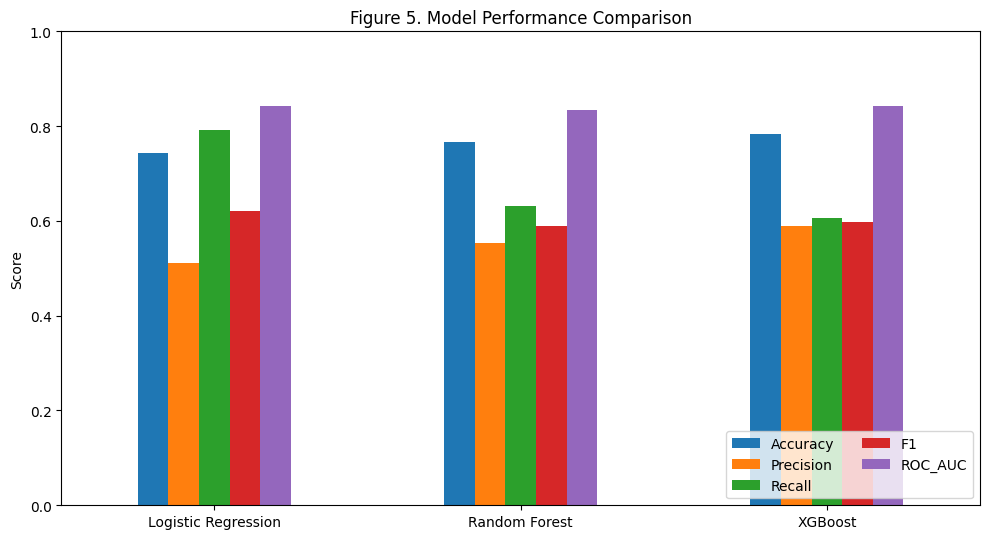

In [16]:
results = pd.DataFrame([
    dummy_result,
    lr_result,
    rf_result,
    xgb_result
]).set_index("Model")

display(results.round(4))

plot_results = results.drop(index="Dummy Baseline")
fig, ax = plt.subplots(figsize=(10, 5.5))
plot_results[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]].plot(
    kind="bar", ax=ax
)
ax.set_title("Figure 5. Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

## 14. Confusion Matrices

Confusion matrices show correct predictions and classification errors for each model, including false positives and false negatives.


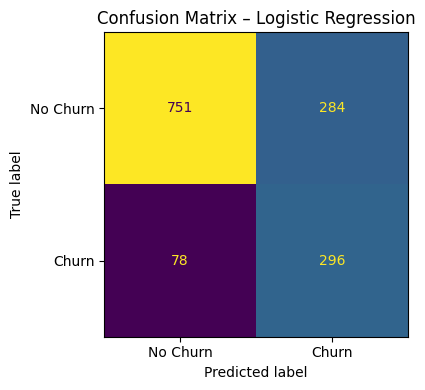

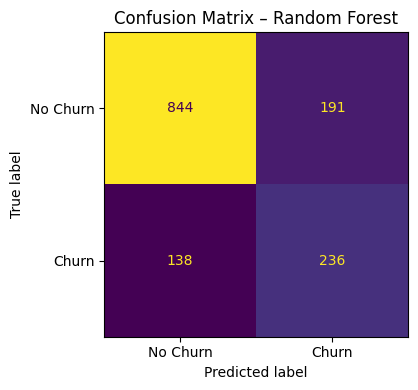

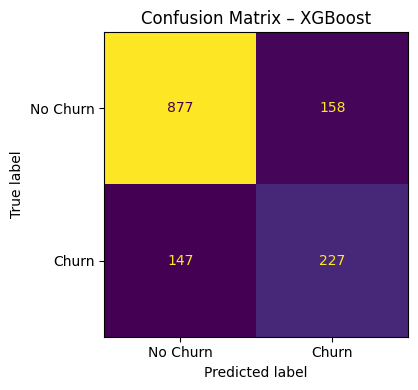

In [17]:
model_predictions = {
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred
}

for name, pred in model_predictions.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        display_labels=["No Churn", "Churn"],
        ax=ax,
        colorbar=False
    )
    ax.set_title(f"Confusion Matrix – {name}")
    plt.tight_layout()
    plt.show()

## 15. Combined ROC Curves

ROC curves compare how well each model separates churners from non-churners across classification thresholds.


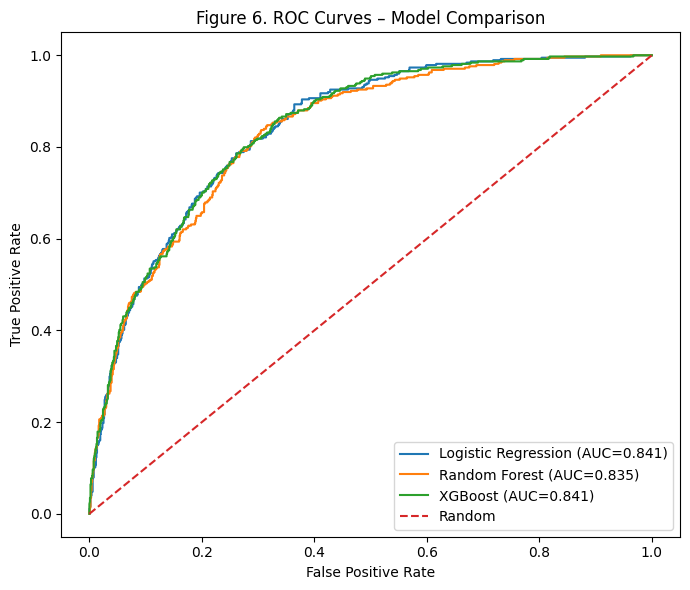

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))

for name, probs in {
    "Logistic Regression": lr_prob,
    "Random Forest": rf_prob,
    "XGBoost": xgb_prob
}.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", label="Random")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Figure 6. ROC Curves – Model Comparison")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 16. Five-Fold Cross-Validation

Five-fold stratified cross-validation checks whether performance remains consistent across different portions of the training data. SMOTE is applied within each training fold to avoid leakage.


In [19]:
cv_models = {
    "Logistic Regression": lr_pipe,
    "Random Forest": rf_best,
    "XGBoost": xgb_pipe
}

cv_rows = []

for name, model in cv_models.items():
    auc_scores = cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="roc_auc", n_jobs=1
    )
    f1_scores = cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="f1", n_jobs=1
    )
    cv_rows.append({
        "Model": name,
        "CV ROC-AUC Mean": auc_scores.mean(),
        "CV ROC-AUC Std": auc_scores.std(),
        "CV F1 Mean": f1_scores.mean(),
        "CV F1 Std": f1_scores.std()
    })

cv_results = pd.DataFrame(cv_rows).set_index("Model")
display(cv_results.round(4))

,CV ROC-AUC Mean,CV ROC-AUC Std,CV F1 Mean,CV F1 Std
Model,,,,
Logistic Regression,0.8447,0.0120,0.6290,0.0218
Random Forest,0.8381,0.0079,0.6149,0.0172
XGBoost,0.8423,0.0102,0.6151,0.0228


## 17. Feature Importance

Random Forest feature importance identifies variables that contribute most to prediction. Feature importance indicates predictive value, not causation.


,Feature,Importance
0,Contract_Month-to-month,0.111711
1,OnlineSecurity_No,0.081213
2,tenure,0.078378
3,TotalCharges,0.058143
4,MonthlyCharges,0.054433
5,Contract_Two year,0.052722
6,TechSupport_No,0.046576
7,InternetService_Fiber optic,0.038159
8,TenureGroup_0-12,0.036475
9,OnlineBackup_No,0.028496


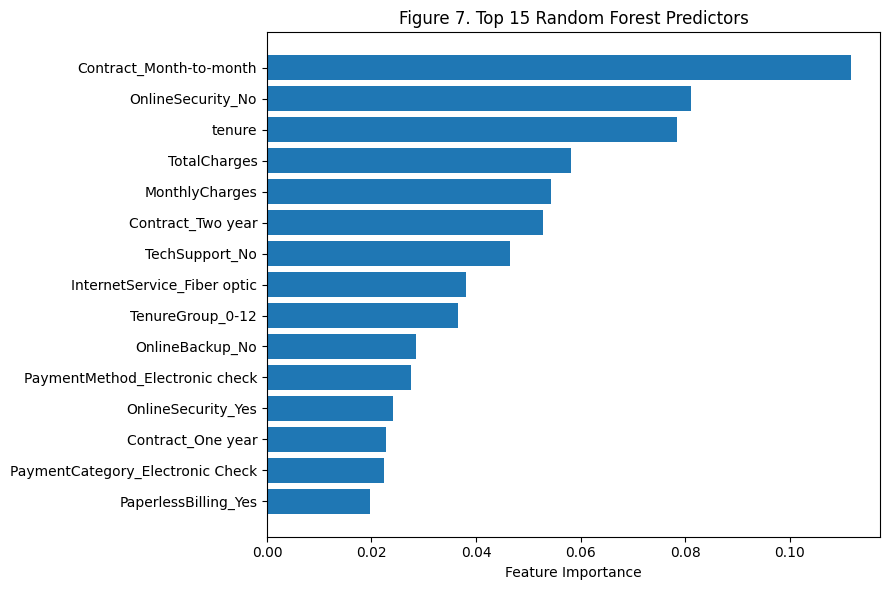

In [20]:
# Extract transformed feature names from the fitted best Random Forest pipeline.
rf_preprocessor = rf_best.named_steps["preprocess"]
feature_names = rf_preprocessor.get_feature_names_out()
rf_model = rf_best.named_steps["model"]

importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": rf_model.feature_importances_
    })
    .sort_values("Importance", ascending=False)
    .head(15)
)

# Make names easier to read.
importance["Feature"] = (
    importance["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

display(importance.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 6))
ordered = importance.sort_values("Importance")
ax.barh(ordered["Feature"], ordered["Importance"])
ax.set_title("Figure 7. Top 15 Random Forest Predictors")
ax.set_xlabel("Feature Importance")
plt.tight_layout()
plt.show()

## 18. Threshold Analysis

Different probability thresholds are tested for Logistic Regression to show the trade-off between precision and recall.


,Threshold,Precision,Recall,F1,Predicted Churn Customers
0,0.30,0.4330,0.9251,0.5899,799
1,0.35,0.4550,0.9064,0.6059,745
2,0.40,0.4685,0.8743,0.6101,698
3,0.45,0.4865,0.8209,0.6109,631
4,0.50,0.5103,0.7914,0.6205,580
5,0.55,0.5346,0.7433,0.6219,520
6,0.60,0.5563,0.7005,0.6201,471
7,0.65,0.5795,0.6337,0.6054,409
8,0.70,0.6034,0.5775,0.5902,358


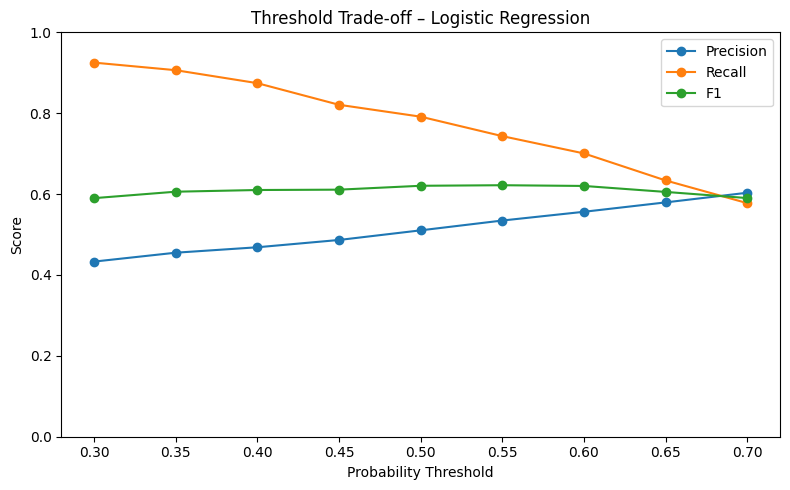

In [21]:
threshold_rows = []

for threshold in np.arange(0.30, 0.71, 0.05):
    pred_t = (lr_prob >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(y_test, pred_t, zero_division=0),
        "Recall": recall_score(y_test, pred_t, zero_division=0),
        "F1": f1_score(y_test, pred_t, zero_division=0),
        "Predicted Churn Customers": int(pred_t.sum())
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(threshold_results["Threshold"], threshold_results["Precision"], marker="o", label="Precision")
ax.plot(threshold_results["Threshold"], threshold_results["Recall"], marker="o", label="Recall")
ax.plot(threshold_results["Threshold"], threshold_results["F1"], marker="o", label="F1")
ax.set_title("Threshold Trade-off – Logistic Regression")
ax.set_xlabel("Probability Threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

## 19. Research Question Review

### Question 1: Which customer characteristics and service attributes are the strongest predictors of churn?

The Random Forest feature-importance results show that *month-to-month contract* was the strongest predictor of churn. Other important predictors included *OnlineSecurity, tenure, TotalCharges, MonthlyCharges, two-year contracts, TechSupport, fiber-optic internet, and OnlineBackup*.

These results show that churn prediction depends on a combination of contract terms, customer relationship length, charges, and subscribed services. Feature importance represents predictive value and does not mean that these variables directly cause churn.

### Question 2: What relationships exist between contract type, tenure, monthly charges, subscribed services, and churn?

Contract type showed a clear relationship with churn. The churn rate was *42.71% for month-to-month customers*, compared with *11.27% for one-year contracts* and *2.83% for two-year contracts*.

Tenure and monthly charges also showed noticeable patterns. Customers with shorter tenure generally had higher churn rates. The highest observed churn rate in the tenure and monthly-charge analysis was *75.7% among customers with 0–12 months of tenure and monthly charges between $91 and $120*.

The feature-importance results also show that services such as OnlineSecurity and TechSupport provide useful information for predicting churn.

### Question 3: How effectively can the models distinguish customers who churn from customers who remain?

All three classification models provided useful predictive performance. The Dummy Classifier produced an accuracy of *73.46%*, but its churn recall was *0%*, meaning that it failed to identify customers who actually churned.

Logistic Regression achieved a *ROC-AUC of 0.8414*, Random Forest achieved *0.8346*, and XGBoost achieved *0.8415*. These results show that the customer variables contain useful information for distinguishing churners from non-churners.

### Question 4: Which classification model provides the strongest performance?

The models performed differently depending on the evaluation metric.

*XGBoost* produced the highest overall accuracy at *78.35%* and the highest precision at *58.96%*, with a ROC-AUC of *0.8415*.

*Logistic Regression* produced the highest recall at *79.14%* and the highest F1-score at *0.6205*, with a ROC-AUC of *0.8414*.

*Random Forest* achieved *76.65% accuracy*, *55.27% precision*, *63.10% recall*, an F1-score of *0.5893*, and a ROC-AUC of *0.8346*.

For a retention application, Logistic Regression is useful when identifying more actual churners is important. XGBoost performs better when overall accuracy and precision are emphasized. The model choice, therefore, depends on the business objective and the cost of false positives and false negatives.

### Question 5: What customer-retention actions can be supported by the results?

Retention efforts can focus on customer groups showing higher predicted churn risk. Particular attention can be given to *month-to-month customers, customers with shorter tenure, customers with higher monthly charges, and customers with service characteristics associated with higher churn risk*.

Predictions should be used to prioritize customers for review rather than automatically determine customer treatment. Retention actions should also be measured to determine whether they actually reduce churn.

## 20. Business Recommendations

Based on the analysis, the following actions can be considered for customer-retention efforts:

1. **Focus on customers with shorter tenure**-Customers in the earlier stages of their relationship showed higher churn rates. Additional support or customer check-ins during the first year may help identify service concerns before customers leave.

2. **Review month-to-month customers**-Month-to-month customers had a churn rate of *42.71%*, compared with *11.27% for one-year contracts* and *2.83% for two-year contracts*. Appropriate incentives or service benefits can be evaluated for customers interested in longer-term contracts.

3. **Review customers with higher monthly charges**-Customers with *0–12 months of tenure and monthly charges between $91 and $120 had a 75.7% observed churn rate* in the grouped analysis. This group may benefit from service or value reviews.

4. **Consider service-related patterns**-OnlineSecurity, TechSupport, internet service, and OnlineBackup appeared among the important predictive features. These variables can be considered when reviewing customer experience and service needs.

5. **Use churn probabilities to prioritize retention efforts.** Predicted churn risk can help identify customers who may need additional review or outreach.

6. **Measure retention results**-A high churn-risk prediction does not prove that an intervention will prevent churn. Retention programs should track customer responses, actual churn, and intervention costs to assess the effectiveness of actions.

## 21. Assumptions, Limitations, Challenges, and Ethics

### Assumptions

The analysis assumes that the customer information and churn labels in the dataset are accurate. It also assumes that the training and test data represent customers from the same general population. Historical customer behavior is assumed to provide useful information for predicting similar customer behavior, although customer patterns may change over time.

### Limitations

The dataset is a public telecommunications sample and may not represent every telecommunications company, geographic region, customer population, or current market condition. It also does not include several factors that could influence churn, including customer complaints, network outages, competitor offers, customer satisfaction, and detailed customer service interactions.

The results identify associations and predictive relationships, not causes. For example, the higher churn rate among month-to-month customers does not prove that the contract type itself causes churn.

SMOTE creates synthetic examples of the minority churn class to augment the training set. These observations help address class imbalance but do not represent actual customers.

### Challenges

One major challenge was *class imbalance*. Approximately 26.5% of customers churned, while approximately 73.5% did not. The Dummy Classifier demonstrated why this matters: it achieved *73.46% accuracy* by predicting the majority class but had *0% recall for churn*.

SMOTE was used during training to help the models learn from the minority churn class. Multiple evaluation metrics were also used rather than relying solely on accuracy.

Another challenge involved *TotalCharges*, which contained blank values and was initially stored as text. The variable was converted to numeric, and the resulting missing values were handled through median imputation during preprocessing.

Model comparison was also a challenge because no model performed best on every metric. XGBoost had higher accuracy and precision, while Logistic Regression had higher recall and F1-score. The appropriate model, therefore, depends on the business objective.

### Ethical Assessment

#### Identify

The main ethical concerns are *customer privacy, model bias and fairness, incorrect predictions, data validity, and misuse of predictions*. The analysis changes the original data through numeric conversion, imputation, one-hot encoding, standardization, feature engineering, and SMOTE.

#### Assess

Privacy risk is relatively low for this academic analysis because the public dataset does not contain direct customer identifiers used by the model. In a real telecommunications environment, customer information could be sensitive, making the potential impact of unauthorized access much greater.

Bias and fairness are concerns because historical customer data may contain patterns that differ across customer groups. Incorrect predictions are expected because none of the models achieved perfect performance. False positives may cause unnecessary retention outreach, while false negatives may result in customers at risk of leaving being missed.

The model could also be misused if churn predictions were treated as facts or used to justify unfair pricing, service restrictions, or other unfavorable treatment.

#### Mitigate

Customer information should be protected through appropriate access controls, data minimization, security practices, and applicable privacy and consumer-protection requirements. Model performance should be reviewed across relevant customer groups to identify possible differences in outcomes.

Predictions should be treated as *estimated churn risk rather than certainty*. Human review should remain part of decisions that could significantly affect customers.

All preprocessing steps, assumptions, exclusions, and limitations should be documented. SMOTE should remain limited to training data, and model performance should continue to be evaluated using untouched test data.

## 22. Code & Reproducibility

The notebook contains the complete analysis needed to reproduce the project results. The workflow includes loading and inspecting the dataset, cleaning the data, exploratory analysis, feature engineering, preprocessing, train/test splitting, class balancing, model training, model evaluation, cross-validation, feature importance, and threshold analysis.

An *80/20 stratified train/test split* is used to maintain the churn distribution in both datasets. A fixed *RANDOM_STATE = 42* is used where applicable to make the results reproducible.

Numeric variables are imputed and standardized, while categorical variables are imputed and one-hot encoded. These preprocessing steps are included in the modeling pipelines so that transformations are learned from the appropriate training data.

SMOTE is applied only within the training workflow. During five-fold cross-validation, SMOTE is also performed within each training fold rather than before cross-validation. This prevents information from the validation or test data from influencing model training.

The notebook trains and evaluates a *Dummy Classifier, Logistic Regression, Random Forest, and XGBoost*. Random Forest parameters are selected using GridSearchCV. All predictive models are evaluated using the same untouched test set with accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices.

In [22]:
# Final summary
print("FINAL TEST-SET MODEL RESULTS")
display(results.round(4))

print("\nFINAL CROSS-VALIDATION RESULTS")
display(cv_results.round(4))

print("\nTOP PREDICTORS")
display(importance.head(10).reset_index(drop=True))

FINAL TEST-SET MODEL RESULTS


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Dummy Baseline,0.7346,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.7431,0.5103,0.7914,0.6205,0.8414
Random Forest,0.7665,0.5527,0.6310,0.5893,0.8346
XGBoost,0.7835,0.5896,0.6070,0.5982,0.8415



FINAL CROSS-VALIDATION RESULTS


,CV ROC-AUC Mean,CV ROC-AUC Std,CV F1 Mean,CV F1 Std
Model,,,,
Logistic Regression,0.8447,0.0120,0.6290,0.0218
Random Forest,0.8381,0.0079,0.6149,0.0172
XGBoost,0.8423,0.0102,0.6151,0.0228



TOP PREDICTORS


,Feature,Importance
0,Contract_Month-to-month,0.111711
1,OnlineSecurity_No,0.081213
2,tenure,0.078378
3,TotalCharges,0.058143
4,MonthlyCharges,0.054433
5,Contract_Two year,0.052722
6,TechSupport_No,0.046576
7,InternetService_Fiber optic,0.038159
8,TenureGroup_0-12,0.036475
9,OnlineBackup_No,0.028496
